1. download the new matched preganancies file from github (Chelsea)

2. Calculate S4 (Jerold)

3. Trim EHG recordings (Michael)

4. Save the new dataset as Matched and Trimmed


In [ ]:
# Libraries we need:
import zipfile
import pandas as pd
from pathlib import Path
import numpy as np
import shutil


## Step 1: Download the Output from Notebook 1 from GitHub

In [ ]:
# Clone our BMEN 600 group's GitHub repository into Colab.
!git clone https://github.com/chelseataylor1/BMEN-600-Group-19.git


fatal: destination path 'BMEN-600-Group-19' already exists and is not an empty directory.


In [ ]:
# Locate the output of Notebook 1 in the GitHub repository.
zip_path = Path(
    "/content/BMEN-600-Group-19/data/processed/"
    "OutputFromNotebook1_EHG_Dataset.zip"
)

# Extract the dataset.
with zipfile.ZipFile(zip_path, "r") as zip_file:
    zip_file.extractall("/content")

# Define the locations of the extracted files.
dataset_path = Path("/content/BMEN600_Matched_EHG_Dataset")
recordings_path = dataset_path / "recordings"
metadata_path = dataset_path / "matched_pregnancies.csv"

print("Dataset extracted successfully!")
print("Recordings:", recordings_path)
print("Metadata:", metadata_path)


Dataset extracted successfully!
Recordings: /content/BMEN600_Matched_EHG_Dataset/recordings
Metadata: /content/BMEN600_Matched_EHG_Dataset/matched_pregnancies.csv


In [ ]:
# Load the Matched Pregnancy Metadata
df_matched = pd.read_csv(metadata_path)

# Confirm the metadata loaded successfully.
print("Matched pregnancies loaded:", len(df_matched))

# Preview the metadata.
display(df_matched.head())

Matched pregnancies loaded: 35


,pregnancy_id,age,early_id,early_week,weight_early,later_id,later_week,weight_later,height,placenta,gestation,newborn_weight,outcome,weeks_between
0,17,22,620,23.9,73,1529,31.9,81,168,end,41.1,3930,induced,8.0
1,18,38,656,22.4,77,1385,31.1,82,167,end,41.3,3710,induced,8.7
2,19,26,665,23.1,83,664,30.4,84,165,front,37.1,2860,induced,7.3
3,20,32,757,22.4,68,756,30.6,72,162,end,39.7,3500,induced,8.2
4,21,29,774,25.0,77,775,31.1,83,171,front,41.6,3180,induced,6.1


## Step 2: Calculating S4

In [ ]:
!pip install wfdb

In [ ]:
# Locate all 70 participant files (.hea or .dat ID's) in Matched Pregnancy Metadata
record_files = list(recordings_path.rglob("*.hea"))
record_ids = [file.stem for file in record_files]

print(f"Total records found: {len(record_ids)}")
print("Record IDs:", pd.DataFrame(record_ids))

Total records found: 70
Record IDs:             0
0   icehg1040
1    icehg775
2   icehg1529
3   icehg1184
4    icehg668
..        ...
65  icehg1430
66  icehg1473
67  icehg1141
68  icehg1096
69   icehg647

[70 rows x 1 columns]


In [ ]:
# Differentiating the Filtered: S1, S2, & S3 Signals

import wfdb

# Search for the record file anywhere inside the recordings subfolders
sample_rec_id = "icehg799"
matching_files = list(recordings_path.rglob(f"{sample_rec_id}.hea"))

if matching_files:
    # Get the parent folder and stem name (without extension)
    sample_path = matching_files[0].parent / matching_files[0].stem

    # Read the record using wfdb
    record = wfdb.rdrecord(str(sample_path))

    print(f"Record ID: {sample_rec_id}")
    print(f"Signal Names (channels): {record.sig_name}")
    print(f"Sampling Frequency: {record.fs} Hz")
    print(f"Signal Units: {record.units}")
    print(f"Signal Array Shape (samples x channels): {record.p_signal.shape}")
else:
    print(f"Could not find record {sample_rec_id}")

Record ID: icehg799
Signal Names (channels): ['S1', 'S1_DOCFILT-4-0.08-5', 'S2', 'S2_DOCFILT-4-0.08-5', 'S3', 'S3_DOCFILT-4-0.08-5']
Sampling Frequency: 20 Hz
Signal Units: ['mV', 'mV', 'mV', 'mV', 'mV', 'mV']
Signal Array Shape (samples x channels): (35280, 6)


**FORMULA:
(Filtered S4) = (Filtered: S1−S2+S3)**

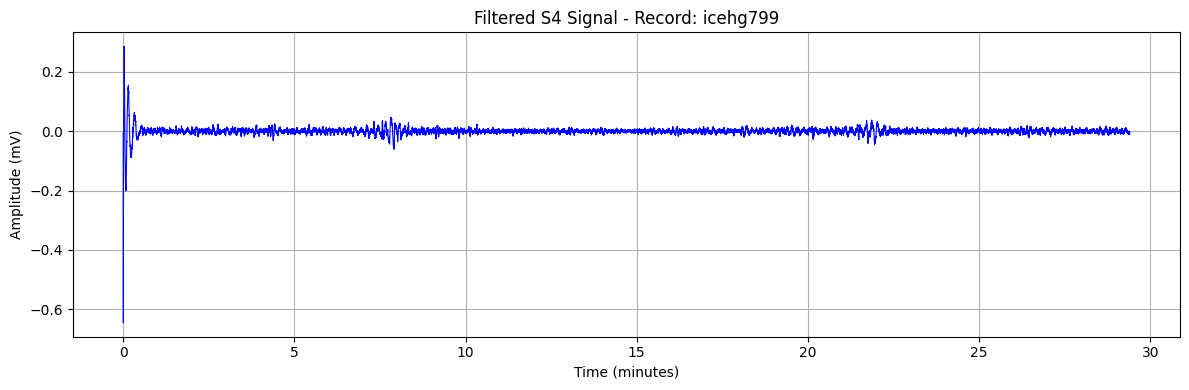

In [ ]:
# Calculating FILTERED S4 Signal, & Plotting as Sample EHG
import matplotlib.pyplot as plt
import wfdb

# Choosing a sample record ID
record_id = "icehg799"

# Finding the file path
record_files = list(recordings_path.rglob(f"{record_id}.hea"))

if record_files:
    record_path = record_files[0].parent / record_files[0].stem
    record = wfdb.rdrecord(str(record_path))
    fs = record.fs  # Sampling frequency in Hz

    # Extract the pre-filtered channels
    s1_filt = record.p_signal[:, record.sig_name.index('S1_DOCFILT-4-0.08-5')]
    s2_filt = record.p_signal[:, record.sig_name.index('S2_DOCFILT-4-0.08-5')]
    s3_filt = record.p_signal[:, record.sig_name.index('S3_DOCFILT-4-0.08-5')]

    # Computing S4 using the filtered channels
    s4_filtered = s1_filt - s2_filt + s3_filt

    # Converting time axis in minutes
    time = [i / (fs * 60) for i in range(len(s4_filtered))]

    # Plotting
    plt.figure(figsize=(12, 4))
    plt.plot(time, s4_filtered, color='BLUE', linewidth=0.8)
    plt.title(f"Filtered S4 Signal - Record: {record_id}")
    plt.xlabel("Time (minutes)")
    plt.ylabel("Amplitude (mV)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print(f"Record {record_id} not found.")

In [ ]:
# Computing Filtered S4 for all records
filtered_s4_results = {}
record_files = list(recordings_path.rglob("*.hea"))

for file in record_files:
    rec_id = file.stem
    rec_path = file.parent / rec_id

    try:
        record = wfdb.rdrecord(str(rec_path))
        fs = record.fs  # Sampling frequency in Hz

        # Extract the pre-filtered channels
        s1_filt = record.p_signal[:, record.sig_name.index('S1_DOCFILT-4-0.08-5')]
        s2_filt = record.p_signal[:, record.sig_name.index('S2_DOCFILT-4-0.08-5')]
        s3_filt = record.p_signal[:, record.sig_name.index('S3_DOCFILT-4-0.08-5')]

        # Compute S4: S1 - S2 + S3
        s4_filtered = s1_filt - s2_filt + s3_filt

        # Store in the dictionary
        filtered_s4_results[rec_id] = {
            "signal": s4_filtered,
            "fs": fs
        }
    except Exception as e:
        print(f"Error processing {rec_id}: {e}")

print(f"Successfully calculated filtered S4 for {len(filtered_s4_results)} records!")

Successfully calculated filtered S4 for 70 records!


## Step 3: Trim EHG Recordings

In [ ]:
#remove the first and last 150 seconds (2.5 minutes)

#need to create time variable for x axis
#figure out the indexing for removing the first and last 2.5 minutes
#use that same indexing to remove the corresponding filtered S1, S2, S3, and S4 values
#trimmed time and signals should be new variables

In [ ]:
#just trying to understand how the results of the previous section were saved
print(filtered_s4_results)
print(filtered_s4_results[rec_id])
print(rec_id)
print(filtered_s4_results[rec_id]["signal"])
print(filtered_s4_results[rec_id]["fs"])

{'icehg1040': {'signal': array([ 0.00183108,  0.01571679,  0.06134127, ..., -0.00801099,
       -0.00709545, -0.00633249], shape=(35260,)), 'fs': 20}, 'icehg775': {'signal': array([0.00091554, 0.00831617, 0.0327306 , ..., 0.0608072 , 0.06157015,
       0.06332494], shape=(35140,)), 'fs': 20}, 'icehg1529': {'signal': array([0.00083925, 0.00709545, 0.02792401, ..., 0.00991836, 0.01029984,
       0.01052873], shape=(38220,)), 'fs': 20}, 'icehg1184': {'signal': array([-0.00083925, -0.00762951, -0.0296788 , ...,  0.00511177,
        0.00343328,  0.00061036], shape=(35200,)), 'fs': 20}, 'icehg668': {'signal': array([-0.00183108, -0.01586938, -0.06218051, ...,  0.00328069,
        0.00259403,  0.00076295], shape=(35160,)), 'fs': 20}, 'icehg1059': {'signal': array([-0.00137331, -0.01213092, -0.04745556, ..., -0.02426184,
       -0.02830549, -0.03059434], shape=(35460,)), 'fs': 20}, 'icehg756': {'signal': array([-0.00068666, -0.00587472, -0.02273594, ...,  0.00419623,
        0.0047303 ,  0.006

In [ ]:
#checking that I know how to access stuff in a dictionary
print(filtered_s4_results[rec_id]["signal"])
print(filtered_s4_results[rec_id]["signal"][0])
print(len(filtered_s4_results[rec_id]["signal"])) #35360
print(filtered_s4_results[rec_id]["signal"][35359])
print(filtered_s4_results[rec_id]["signal"][len(filtered_s4_results[rec_id]["signal"])-1])

#trimmed_S4.append(filtered_s4_results[rec_id]["signal"][trimmed_index[j]])

[0.00015259 0.00053407 0.00244144 ... 0.00755322 0.00633249 0.00297551]
0.00015259021896696422
35360
0.002975509269855802
0.002975509269855802


In [ ]:
#trimming time, s1, s2, s3, and s4 to remove the first and last 2.5 minutes
#some of the code is copied from previous sections
trimmed_results = {}
record_files = list(recordings_path.rglob("*.hea"))
for file in record_files:
    rec_id = file.stem
    rec_path = file.parent / rec_id

    record = wfdb.rdrecord(str(rec_path))
    fs = filtered_s4_results[rec_id]["fs"]  # Sampling frequency in Hz

    # Converting time axis in minutes
    time = [i / (fs * 60) for i in range(len(filtered_s4_results[rec_id]["signal"]))]

    # Extract the pre-filtered channels
    s1_filt = record.p_signal[:, record.sig_name.index('S1_DOCFILT-4-0.08-5')]
    s2_filt = record.p_signal[:, record.sig_name.index('S2_DOCFILT-4-0.08-5')]
    s3_filt = record.p_signal[:, record.sig_name.index('S3_DOCFILT-4-0.08-5')]

    #trimming time and tracking the index for use in trimming the signals
    trimmed_time = []
    trimmed_index = []
    i=0
    while i < len(time):
      if time[i] <= 2.5:
        i = i+1
      elif time[i] <= time[-1] - 2.5:
        trimmed_index.append(i)
        trimmed_time.append(time[i])
        i = i+1
      else:
        break

    #trimming the signals by the same amount as the time was trimmed
    j=0
    trimmed_S1 = []
    trimmed_S2 =[]
    trimmed_S3 =[]
    trimmed_S4 =[]
    while j < len(trimmed_index):
      trimmed_S1.append(s1_filt[trimmed_index[j]])
      trimmed_S2.append(s2_filt[trimmed_index[j]])
      trimmed_S3.append(s3_filt[trimmed_index[j]])
      trimmed_S4.append(filtered_s4_results[rec_id]["signal"][trimmed_index[j]])
      j = j+1

    trimmed_results[rec_id] = {
        "trimmed_time": trimmed_time,
        "trimmed_S1": trimmed_S1,
        "trimmed_S2": trimmed_S2,
        "trimmed_S3": trimmed_S3,
        "trimmed_S4": trimmed_S4,
    }

In [ ]:
#checking the length. making sure x and y axis will have the same amount of values when plotted
for rec_id in trimmed_results:
    print(f"Record ID: {rec_id}")
    print(len(trimmed_results[rec_id]["trimmed_time"]))
    print(len(trimmed_results[rec_id]["trimmed_S1"]))
    print(len(trimmed_results[rec_id]["trimmed_S2"]))
    print(len(trimmed_results[rec_id]["trimmed_S3"]))
    print(len(trimmed_results[rec_id]["trimmed_S4"]))
    print()

Record ID: icehg1040
29259
29259
29259
29259
29259

Record ID: icehg775
29139
29139
29139
29139
29139

Record ID: icehg1529
32219
32219
32219
32219
32219

Record ID: icehg1184
29199
29199
29199
29199
29199

Record ID: icehg668
29159
29159
29159
29159
29159

Record ID: icehg1059
29459
29459
29459
29459
29459

Record ID: icehg756
29219
29219
29219
29219
29219

Record ID: icehg664
29079
29079
29079
29079
29079

Record ID: icehg989
29319
29319
29319
29319
29319

Record ID: icehg805
29199
29199
29199
29199
29199

Record ID: icehg1238
29259
29259
29259
29259
29259

Record ID: icehg799
29279
29279
29279
29279
29279

Record ID: icehg1527
29999
29999
29999
29999
29999

Record ID: icehg1179
29299
29299
29299
29299
29299

Record ID: icehg956
29459
29459
29459
29459
29459

Record ID: icehg908
29279
29279
29279
29279
29279

Record ID: icehg865
29279
29279
29279
29279
29279

Record ID: icehg1010
29199
29199
29199
29199
29199

Record ID: icehg1385
29998
29998
29998
29998
29998

Record ID: icehg1254
2

In [ ]:
print(trimmed_results.keys())
print(trimmed_results["icehg799"].keys())

dict_keys(['icehg1040', 'icehg775', 'icehg1529', 'icehg1184', 'icehg668', 'icehg1059', 'icehg756', 'icehg664', 'icehg989', 'icehg805', 'icehg1238', 'icehg799', 'icehg1527', 'icehg1179', 'icehg956', 'icehg908', 'icehg865', 'icehg1010', 'icehg1385', 'icehg1254', 'icehg1510', 'icehg1079', 'icehg1580', 'icehg851', 'icehg714', 'icehg675', 'icehg1650', 'icehg654', 'icehg1053', 'icehg650', 'icehg985', 'icehg1330', 'icehg1530', 'icehg1019', 'icehg1098', 'icehg806', 'icehg1185', 'icehg620', 'icehg1081', 'icehg1680', 'icehg1416', 'icehg774', 'icehg1698', 'icehg907', 'icehg757', 'icehg1243', 'icehg1444', 'icehg665', 'icehg1388', 'icehg1361', 'icehg1180', 'icehg958', 'icehg656', 'icehg1449', 'icehg1599', 'icehg1124', 'icehg1011', 'icehg1175', 'icehg657', 'icehg1393', 'icehg673', 'icehg814', 'icehg885', 'icehg1655', 'icehg1218', 'icehg1430', 'icehg1473', 'icehg1141', 'icehg1096', 'icehg647'])
dict_keys(['trimmed_time', 'trimmed_S1', 'trimmed_S2', 'trimmed_S3', 'trimmed_S4'])


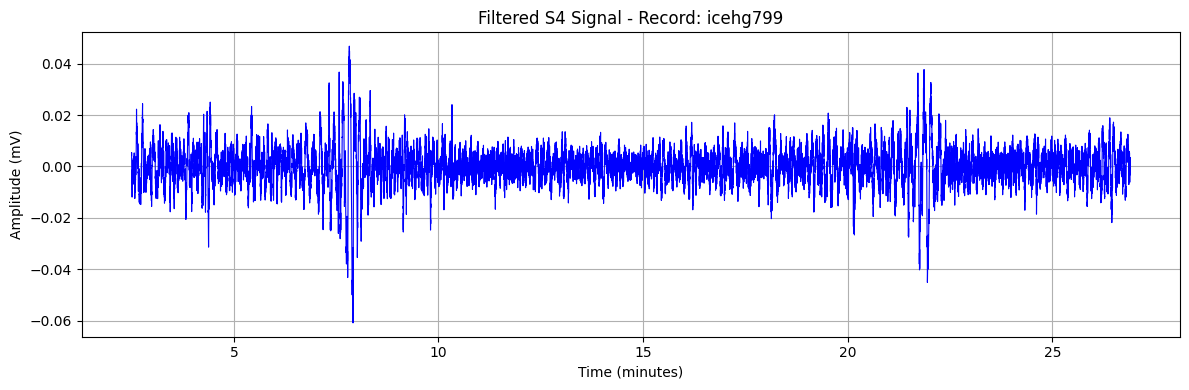

In [ ]:
#checking results with a graph
#code mostly copied from earlier section
plt.figure(figsize=(12, 4))
plt.plot(trimmed_results["icehg799"]["trimmed_time"], trimmed_results["icehg799"]["trimmed_S4"], color='BLUE', linewidth=0.8)
plt.title(f"Filtered S4 Signal - Record: icehg799")
plt.xlabel("Time (minutes)")
plt.ylabel("Amplitude (mV)")
plt.grid(True)
plt.tight_layout()
plt.show()

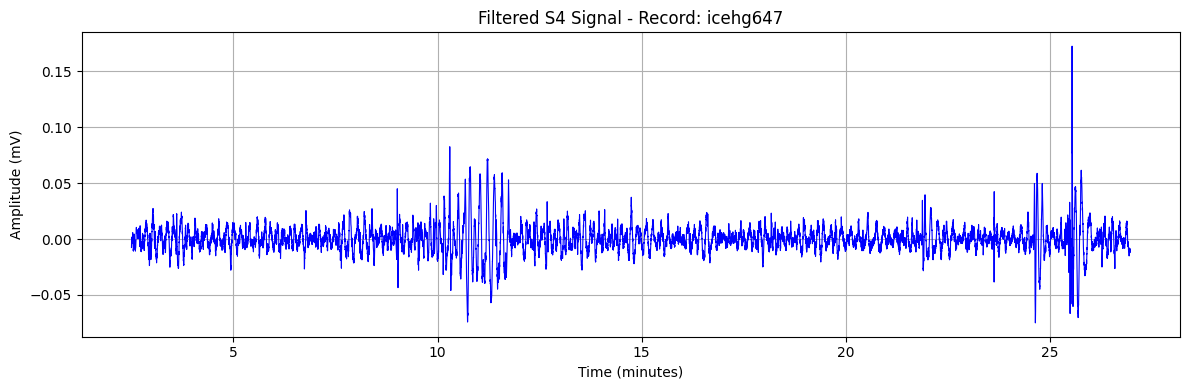

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(trimmed_results["icehg647"]["trimmed_time"], trimmed_results["icehg647"]["trimmed_S4"], color='BLUE', linewidth=0.8)
plt.title(f"Filtered S4 Signal - Record: icehg647")
plt.xlabel("Time (minutes)")
plt.ylabel("Amplitude (mV)")
plt.grid(True)
plt.tight_layout()
plt.show()

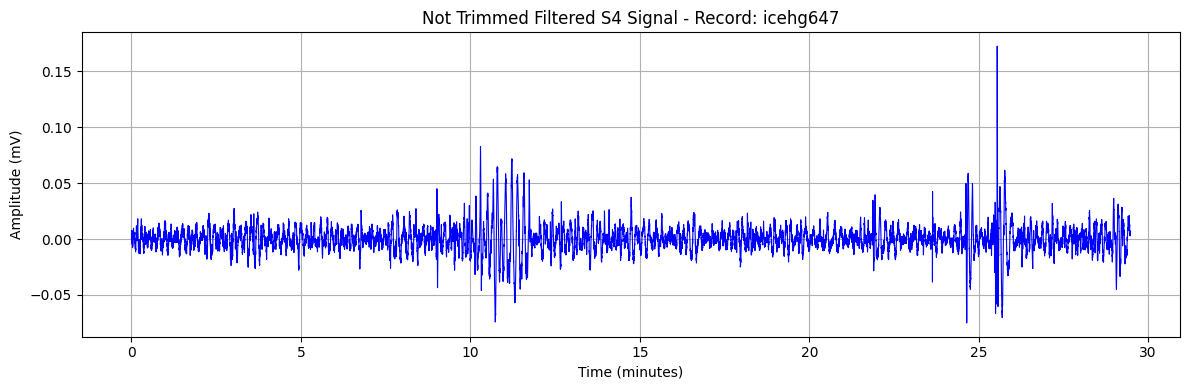

In [ ]:
# Choosing a sample record ID
record_id = "icehg647"

# Finding the file path
record_files = list(recordings_path.rglob(f"{record_id}.hea"))

if record_files:
    record_path = record_files[0].parent / record_files[0].stem
    record = wfdb.rdrecord(str(record_path))
    fs = record.fs  # Sampling frequency in Hz

    # Extract the pre-filtered channels
    s1_filt = record.p_signal[:, record.sig_name.index('S1_DOCFILT-4-0.08-5')]
    s2_filt = record.p_signal[:, record.sig_name.index('S2_DOCFILT-4-0.08-5')]
    s3_filt = record.p_signal[:, record.sig_name.index('S3_DOCFILT-4-0.08-5')]

    # Computing S4 using the filtered channels
    s4_filtered = s1_filt - s2_filt + s3_filt

    # Converting time axis in minutes
    time = [i / (fs * 60) for i in range(len(s4_filtered))]

    # Plotting
    plt.figure(figsize=(12, 4))
    plt.plot(time, s4_filtered, color='BLUE', linewidth=0.8)
    plt.title(f"Not Trimmed Filtered S4 Signal - Record: icehg647")
    plt.xlabel("Time (minutes)")
    plt.ylabel("Amplitude (mV)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print(f"Record {record_id} not found.")

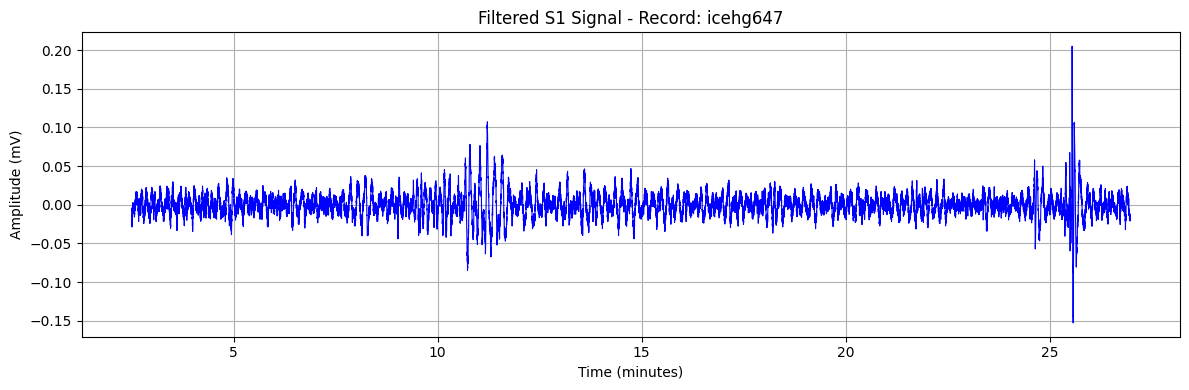

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(trimmed_results["icehg647"]["trimmed_time"], trimmed_results["icehg647"]["trimmed_S1"], color='BLUE', linewidth=0.8)
plt.title(f"Filtered S1 Signal - Record: icehg647")
plt.xlabel("Time (minutes)")
plt.ylabel("Amplitude (mV)")
plt.grid(True)
plt.tight_layout()
plt.show()

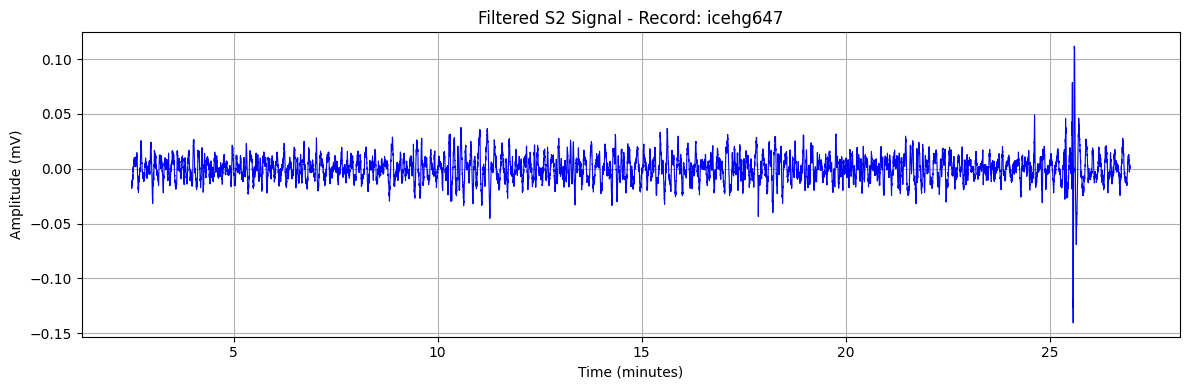

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(trimmed_results["icehg647"]["trimmed_time"], trimmed_results["icehg647"]["trimmed_S2"], color='BLUE', linewidth=0.8)
plt.title(f"Filtered S2 Signal - Record: icehg647")
plt.xlabel("Time (minutes)")
plt.ylabel("Amplitude (mV)")
plt.grid(True)
plt.tight_layout()
plt.show()

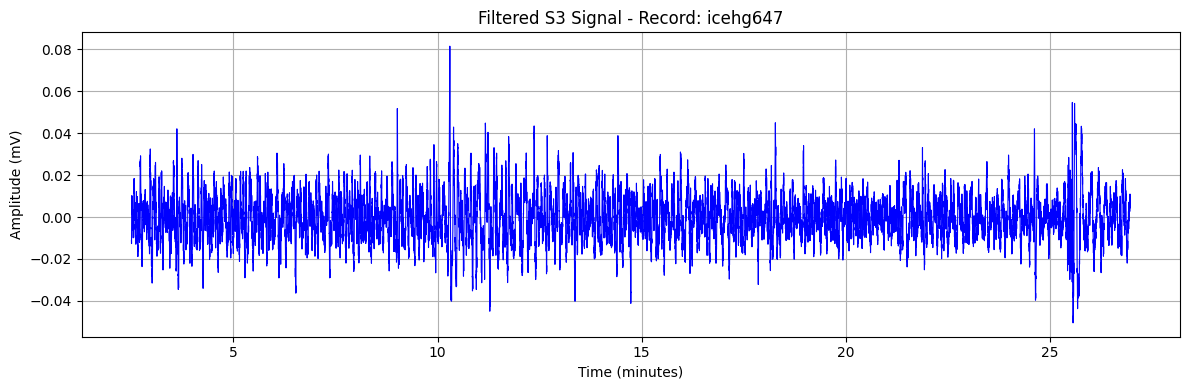

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(trimmed_results["icehg647"]["trimmed_time"], trimmed_results["icehg647"]["trimmed_S3"], color='BLUE', linewidth=0.8)
plt.title(f"Filtered S3 Signal - Record: icehg647")
plt.xlabel("Time (minutes)")
plt.ylabel("Amplitude (mV)")
plt.grid(True)
plt.tight_layout()
plt.show()

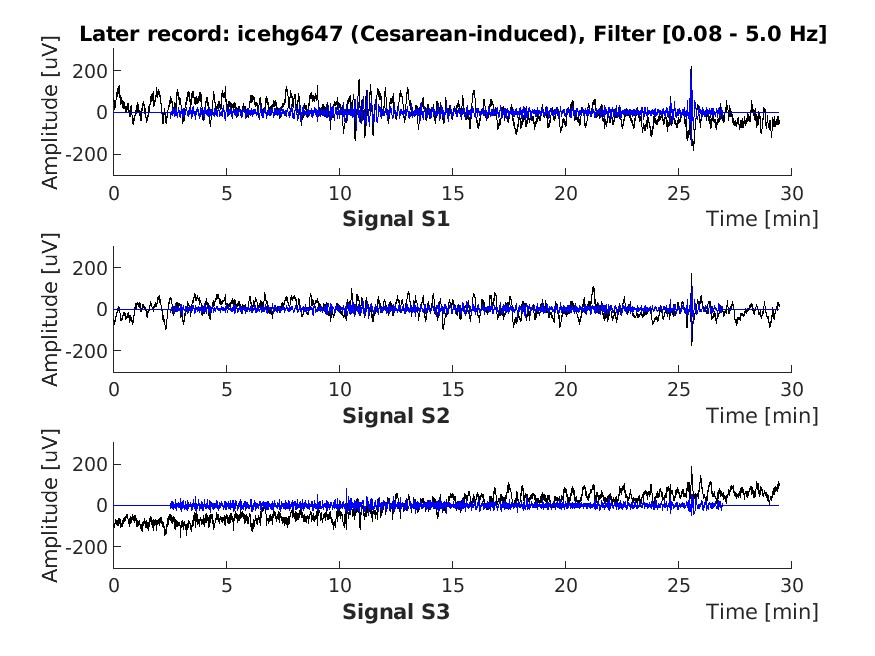

## Step 4: Save the new Dataset

In [ ]:
from google.colab import files
from pathlib import Path
import shutil

# Identify pregnancies with both early and later recordings.
df_export = df_matched.dropna(subset=["early_id", "later_id"]).copy()

# Convert recording IDs to the EHG recording naming format.
df_export["early_rec"] = df_export["early_id"].astype(int).map(
    lambda x: f"icehg{x}"
)
df_export["later_rec"] = df_export["later_id"].astype(int).map(
    lambda x: f"icehg{x}"
)

# Only retain pregnancies for which BOTH processed recordings exist.
df_export = df_export[
    df_export["early_rec"].isin(trimmed_results)
    & df_export["later_rec"].isin(trimmed_results)
].copy()

# Identify the recordings belonging to complete pregnancy pairs.
matched_ids = set(df_export["early_rec"]) | set(df_export["later_rec"])

# Create a clean output folder.
output_path = Path("/content/BMEN600_Matched_Trimmed_EHG_Dataset")
output_recordings = output_path / "recordings"

# Remove previous exports so unmatched recordings are not retained.
if output_path.exists():
    shutil.rmtree(output_path)

output_recordings.mkdir(parents=True, exist_ok=True)

# Save only the matched trimmed EHG recordings.
for rec_id in sorted(matched_ids):
    df = pd.DataFrame(trimmed_results[rec_id])
    df.to_csv(output_recordings / f"{rec_id}.csv", index=False)

# Save metadata for the exported pregnancies only.
df_export.drop(columns=["early_rec", "later_rec"]).to_csv(
    output_path / "matched_pregnancies.csv",
    index=False
)

# Compress the processed dataset into a ZIP file.
zip_output = shutil.make_archive(
    "/content/OutputFromNotebook2_EHG_Dataset",
    "zip",
    root_dir=output_path.parent,
    base_dir=output_path.name
)

# Confirm the exported dataset.
print(f"Matched pregnancies: {len(df_export)}")
print(f"Recordings exported: {len(matched_ids)}")
print(f"ZIP file size: {Path(zip_output).stat().st_size / (1024**2):.2f} MB")
print(f"ZIP file created: {zip_output}")

# Download the ZIP file to your computer.
files.download(zip_output)

Matched pregnancies: 35
Recordings exported: 70
ZIP file size: 32.57 MB
ZIP file created: /content/OutputFromNotebook2_EHG_Dataset.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>